# HIVE VÀ TRỰC QUAN HÓA 

## PHẦN 1: KẾT NỐI SPARK VỚI HIVE

In [1]:
#Khởi tạo lại Spark và kết nối Hive
from pyspark.sql import SparkSession

BASE = "hdfs://namenode:8020"

spark = (
    SparkSession.builder
    .appName("FIFA-Hive-Visualization")
    .config("spark.hadoop.fs.defaultFS", BASE)
    .config("spark.sql.warehouse.dir", f"{BASE}/user/hive/warehouse")
    .config("hive.metastore.uris", "thrift://hive-metastore:9083")
    .config("spark.sql.parquet.writeLegacyFormat", "true")
    .config("spark.driver.memory", "3g")
    .config("spark.sql.shuffle.partitions", "16")
    .config("spark.hadoop.dfs.replication", "1")
    .config("spark.local.dir", "/tmp/spark")
    .enableHiveSupport()
    .getOrCreate()
)

print("Spark version:", spark.version)
print("SparkSession đã được khởi tạo.")

Spark version: 3.5.0
SparkSession đã được khởi tạo.


In [2]:
# Kiểm tra Database và các bảng Hive
print("=== 1. Các database hiện có ===")
spark.sql("SHOW DATABASES").show(truncate=False)

print("\n=== 2. Chọn database fifa ===")
spark.sql("USE fifa")
print("Đã chọn database fifa.")

print("\n=== 3. Các bảng trong database fifa ===")
spark.sql("SHOW TABLES").show(truncate=False)

=== 1. Các database hiện có ===
+---------+
|namespace|
+---------+
|default  |
|fifa     |
+---------+


=== 2. Chọn database fifa ===
Đã chọn database fifa.

=== 3. Các bảng trong database fifa ===
+---------+-------------------+-----------+
|namespace|tableName          |isTemporary|
+---------+-------------------+-----------+
|fifa     |club_summary       |false      |
|fifa     |nationality_summary|false      |
|fifa     |position_summary   |false      |
+---------+-------------------+-----------+



In [3]:
# Kiểm tra các file Parquet trong HDFS (Dữ liệu spark trong HDFS)
hadoop_conf = spark.sparkContext._jsc.hadoopConfiguration()
Path = spark.sparkContext._jvm.org.apache.hadoop.fs.Path

fs = Path("hdfs://namenode:8020/").getFileSystem(hadoop_conf)

root = Path("/fifa/processed")

if fs.exists(root):
    print("Đã tìm thấy thư mục /fifa/processed")

    def list_hdfs(path, depth=0):
        for status in fs.listStatus(path):
            name = status.getPath().toString()
            if status.isDirectory():
                print("  " * depth + "[DIR]  " + name)
                list_hdfs(status.getPath(), depth + 1)
            else:
                print("  " * depth + "[FILE] " + name)

    list_hdfs(root)
else:
    print("Chưa tìm thấy /fifa/processed")
    print("Các thư mục tại /fifa:")
    fifa_root = Path("/fifa")
    if fs.exists(fifa_root):
        for item in fs.listStatus(fifa_root):
            print(item.getPath().toString())
    else:
        print("Thư mục /fifa không tồn tại trong HDFS")

Đã tìm thấy thư mục /fifa/processed
[DIR]  hdfs://namenode:8020/fifa/processed/club_summary
  [FILE] hdfs://namenode:8020/fifa/processed/club_summary/_SUCCESS
  [FILE] hdfs://namenode:8020/fifa/processed/club_summary/part-00000-998953c9-a054-43b5-b6cb-ae08a52ccfac-c000.snappy.parquet
[DIR]  hdfs://namenode:8020/fifa/processed/nationality_summary
  [FILE] hdfs://namenode:8020/fifa/processed/nationality_summary/_SUCCESS
  [FILE] hdfs://namenode:8020/fifa/processed/nationality_summary/part-00000-6657757b-5271-4700-84ef-dc6e34cb2ec4-c000.snappy.parquet
[DIR]  hdfs://namenode:8020/fifa/processed/position_summary
  [FILE] hdfs://namenode:8020/fifa/processed/position_summary/_SUCCESS
  [FILE] hdfs://namenode:8020/fifa/processed/position_summary/part-00000-7e236aec-4c5d-4870-9d09-3b56ce8a2836-c000.snappy.parquet


In [4]:
# Đọc thử dữ liệu và kiểm tra các cột 
base_path = "hdfs://namenode:8020/fifa/processed"

datasets = {
    "club_summary": f"{base_path}/club_summary",
    "nationality_summary": f"{base_path}/nationality_summary",
    "position_summary": f"{base_path}/position_summary"
}

for name, path in datasets.items():
    print("\n" + "=" * 60)
    print(f"BỘ DỮ LIỆU: {name}")
    print("=" * 60)

    df = spark.read.parquet(path)

    print("Cấu trúc cột:")
    df.printSchema()

    print("5 dòng dữ liệu mẫu:")
    df.show(5, truncate=False)

    print("Số dòng:", df.count())


BỘ DỮ LIỆU: club_summary
Cấu trúc cột:
root
 |-- club_name: string (nullable = true)
 |-- total_players: long (nullable = true)
 |-- avg_overall: double (nullable = true)
 |-- avg_wage: double (nullable = true)
 |-- total_value: long (nullable = true)

5 dòng dữ liệu mẫu:
+-------------------+-------------+-----------------+------------------+-----------+
|club_name          |total_players|avg_overall      |avg_wage          |total_value|
+-------------------+-------------+-----------------+------------------+-----------+
|Manchester City    |26           |79.53846153846153|141076.92307692306|1255055000 |
|Liverpool          |59           |72.13559322033899|55795.76271186441 |1138045000 |
|Paris Saint Germain|26           |80.34615384615384|87826.92307692308 |1056575000 |
|Real Madrid        |33           |76.9090909090909 |129318.18181818182|1031050000 |
|FC Barcelona       |37           |75.91891891891892|100216.21621621621|1020625000 |
+-------------------+-------------+-----------

In [5]:
# Xoá và tạo lại 3 bảng. Cả 3 bảng đều là EXTERNAL nên DROP TABLE chỉ xoá định nghĩa trong Hive, dữ liệu Parquet trên HDFS vẫn còn nguyên.
base = "hdfs://namenode:8020/fifa/processed"

spark.sql("USE fifa")

for t in ["nationality_summary", "club_summary", "position_summary"]:
    # Đọc schema thật từ file Parquet trên HDFS
    df = spark.read.parquet(f"{base}/{t}")
    cols = ", ".join(f"`{f.name}` {f.dataType.simpleString()}" for f in df.schema.fields)

    # Xoá định nghĩa bảng cũ (bảng EXTERNAL nên không xoá dữ liệu)
    spark.sql(f"DROP TABLE IF EXISTS fifa.{t}")

    # Tạo lại bảng theo đúng schema mới
    spark.sql(f"""
        CREATE EXTERNAL TABLE fifa.{t} ({cols})
        STORED AS PARQUET
        LOCATION '{base}/{t}'
    """)
    print(f"Đã tạo lại fifa.{t}: {cols}")

print("\nCác bảng hiện có:")
spark.sql("SHOW TABLES").show(truncate=False)

# Kiểm tra số dòng (phải ra 165, 673, 728)
for t in ["nationality_summary", "club_summary", "position_summary"]:
    print(t, "->", spark.sql(f"SELECT COUNT(*) FROM fifa.{t}").collect()[0][0], "dòng")

Đã tạo lại fifa.nationality_summary: `nationality_name` string, `total_players` bigint, `avg_age` double, `avg_overall` double, `total_value` bigint
Đã tạo lại fifa.club_summary: `club_name` string, `total_players` bigint, `avg_overall` double, `avg_wage` double, `total_value` bigint
Đã tạo lại fifa.position_summary: `player_positions` string, `total_players` bigint, `avg_overall` double, `avg_potential` double, `avg_value` double

Các bảng hiện có:
+---------+-------------------+-----------+
|namespace|tableName          |isTemporary|
+---------+-------------------+-----------+
|fifa     |club_summary       |false      |
|fifa     |nationality_summary|false      |
|fifa     |position_summary   |false      |
+---------+-------------------+-----------+

nationality_summary -> 165 dòng
club_summary -> 673 dòng
position_summary -> 728 dòng


# PHẦN 2: TẠO LẬP VÀ KIỂM TRA DỮ LIỆU TRÊN HIVE
## Bước 1: Tạo các bảng Hive

In [6]:
# Đăng ký các bảng Hive từ Parquet trên HDFS
spark.sql("CREATE DATABASE IF NOT EXISTS fifa")

table_paths = {
    "club_summary": "hdfs://namenode:8020/fifa/processed/club_summary",
    "nationality_summary": "hdfs://namenode:8020/fifa/processed/nationality_summary",
    "position_summary": "hdfs://namenode:8020/fifa/processed/position_summary"
}

for table_name, path in table_paths.items():
    spark.sql(f"""
        CREATE TABLE IF NOT EXISTS fifa.{table_name}
        USING PARQUET
        LOCATION '{path}'
    """)
    print(f"Đã kiểm tra/đăng ký bảng: fifa.{table_name}")

print("\nDanh sách bảng Hive:")
spark.sql("SHOW TABLES IN fifa").show(truncate=False)

Đã kiểm tra/đăng ký bảng: fifa.club_summary
Đã kiểm tra/đăng ký bảng: fifa.nationality_summary
Đã kiểm tra/đăng ký bảng: fifa.position_summary

Danh sách bảng Hive:
+---------+-------------------+-----------+
|namespace|tableName          |isTemporary|
+---------+-------------------+-----------+
|fifa     |club_summary       |false      |
|fifa     |nationality_summary|false      |
|fifa     |position_summary   |false      |
+---------+-------------------+-----------+



## Bước 2: Kiểm tra dữ liệu các dòng đầu của bảng Hive
Nếu truy vấn được dữ liệu, phần đăng ký bảng Hive cơ bản đã hoạt động. Tiếp theo, ta sẽ dùng các bảng này để tạo biểu đồ bằng Python.

In [7]:
# Kiểm tra dữ liệu các dòng đầu của bảng Hive
for table_name in ["club_summary", "nationality_summary", "position_summary"]:
    print(f"\n=== {table_name} ===")
    spark.sql(f"SELECT * FROM fifa.{table_name} LIMIT 5").show(truncate=False)


=== club_summary ===
+-------------------+-------------+-----------------+------------------+-----------+
|club_name          |total_players|avg_overall      |avg_wage          |total_value|
+-------------------+-------------+-----------------+------------------+-----------+
|Manchester City    |26           |79.53846153846153|141076.92307692306|1255055000 |
|Liverpool          |59           |72.13559322033899|55795.76271186441 |1138045000 |
|Paris Saint Germain|26           |80.34615384615384|87826.92307692308 |1056575000 |
|Real Madrid        |33           |76.9090909090909 |129318.18181818182|1031050000 |
|FC Barcelona       |37           |75.91891891891892|100216.21621621621|1020625000 |
+-------------------+-------------+-----------------+------------------+-----------+


=== nationality_summary ===
+----------------+-------------+------------------+------------------+-----------+
|nationality_name|total_players|avg_age           |avg_overall       |total_value|
+----------------

## PHẦN 3: TRỰC QUAN HÓA DỮ LIỆU FIFA
### 1. Biểu đồ Bar Chart — Top 10 CLB có mức lương trung bình cao nhất
Câu hỏi phân tích: Những CLB nào có mức lương cầu thủ trung bình cao nhất trong bộ dữ liệu FIFA?
### Bước 1: Truy vấn dữ liệu từ Hive

In [8]:
query_bar = """
SELECT
    club_name,
    avg_wage,
    total_players,
    avg_overall
FROM fifa.club_summary
WHERE club_name IS NOT NULL
  AND avg_wage IS NOT NULL
  AND total_players >= 10  
ORDER BY avg_wage DESC
LIMIT 10
"""

df_bar = spark.sql(query_bar)
df_bar.show(truncate=False)

+-------------------+------------------+-------------+-----------------+
|club_name          |avg_wage          |total_players|avg_overall      |
+-------------------+------------------+-------------+-----------------+
|Manchester City    |141076.92307692306|26           |79.53846153846153|
|Real Madrid        |129318.18181818182|33           |76.9090909090909 |
|FC Barcelona       |100216.21621621621|37           |75.91891891891892|
|Paris Saint Germain|87826.92307692308 |26           |80.34615384615384|
|Chelsea            |86142.85714285714 |35           |76.82857142857142|
|Manchester United  |85666.66666666667 |33           |76.06060606060606|
|Juventus           |76580.64516129032 |31           |77.2258064516129 |
|Tottenham Hotspur  |73433.33333333333 |30           |76.03333333333333|
|FC Bayern München  |61296.2962962963  |27           |78.44444444444444|
|Inter              |60785.71428571428 |28           |78.5             |
+-------------------+------------------+-----------

### Bước 2: Vẽ biểu đồ 

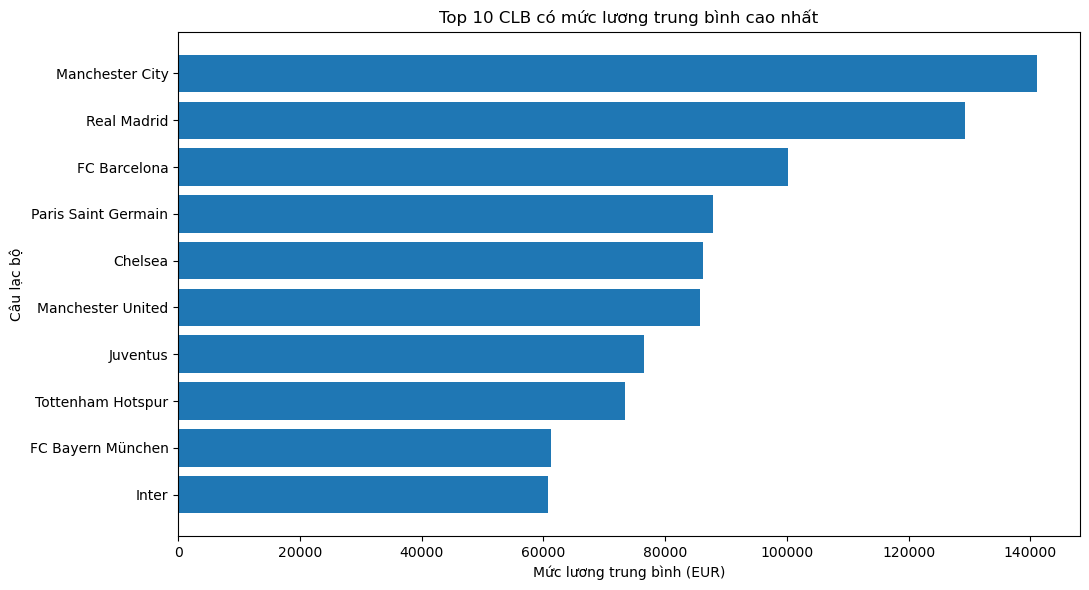

In [9]:
import matplotlib.pyplot as plt

# Chuyển kết quả truy vấn sang Pandas để trực quan hóa
df_bar_pd = df_bar.toPandas()

# Đảo thứ tự để CLB có lương cao nhất nằm ở phía trên
df_bar_pd = df_bar_pd.sort_values(
    "avg_wage", ascending=True
)

plt.figure(figsize=(11, 6))

plt.barh(
    df_bar_pd["club_name"],
    df_bar_pd["avg_wage"]
)

plt.title("Top 10 CLB có mức lương trung bình cao nhất")
plt.xlabel("Mức lương trung bình (EUR)")
plt.ylabel("Câu lạc bộ")
plt.tight_layout()
plt.savefig("top10_club_avg_wage.png", dpi=200, bbox_inches="tight")
plt.show()

### *Kết luận:*
*- Manchester City và Real Madrid là hai câu lạc bộ có mức lương trung bình cao nhất, lần lượt khoảng 141.000 EUR và 129.000 EURm trong đó Manchester City nhỉnh hơn Real Madrid.*

*- FC Barcelona đứng thứ ba với khoảng 100.000 EUR, thấp hơn Real Madrid khoảng 29.000 EUR. Sau đó có một bược giảm rõ rệt xuống nhóm còn lại.*

*- Nhóm từ vị trí thứ tư đến thứ sáu gồm Paris Saint Germain (khoảng 88.000 EUR), Chelsea (khoảng 86.000 EUR) và Manchester United (khoảng 85.500 EUR) có mức lương gần nhau. Juventus (khoảng 76.500 EUR) và Tottenham Hotspur (khoảng 73.500 EUR) tiếp theo.*

*- Bayern München (khoảng 61.000 EUR) và Inter (khoảng 60.500 EUR) ở cuối Top 10, thấp hơn Manchester City khoảng một nửa. Số liệu tính trên dữ liệu phiên bản FIFA mới nhất, mỗi cầu thủ một bản ghi.*

### 2. Scatter Plot — Mối quan hệ giữa mức lương và năng lực cầu thủ theo CLB
Câu hỏi phân tích: Các CLB có mức lương cầu thủ trung bình cao có đồng thời có điểm Overall trung bình cao không?
### Bước 1: Truy vấn dữ liệu từ Hive

In [10]:
query_scatter = """
SELECT
    club_name,
    avg_wage,
    avg_overall
FROM fifa.club_summary
WHERE club_name IS NOT NULL
  AND avg_wage IS NOT NULL
  AND avg_overall IS NOT NULL
"""

df_scatter = spark.sql(query_scatter)
df_scatter.show(10, truncate=False)

print("Số CLB được đưa vào phân tích:", df_scatter.count())

+-------------------+------------------+-----------------+
|club_name          |avg_wage          |avg_overall      |
+-------------------+------------------+-----------------+
|Manchester City    |141076.92307692306|79.53846153846153|
|Liverpool          |55795.76271186441 |72.13559322033899|
|Paris Saint Germain|87826.92307692308 |80.34615384615384|
|Real Madrid        |129318.18181818182|76.9090909090909 |
|FC Barcelona       |100216.21621621621|75.91891891891892|
|FC Bayern München  |61296.2962962963  |78.44444444444444|
|Chelsea            |86142.85714285714 |76.82857142857142|
|Inter              |60785.71428571428 |78.5             |
|Manchester United  |85666.66666666667 |76.06060606060606|
|Milan              |53906.25          |77.28125         |
+-------------------+------------------+-----------------+
only showing top 10 rows

Số CLB được đưa vào phân tích: 673


### Bước 2: Vẽ biểu đồ

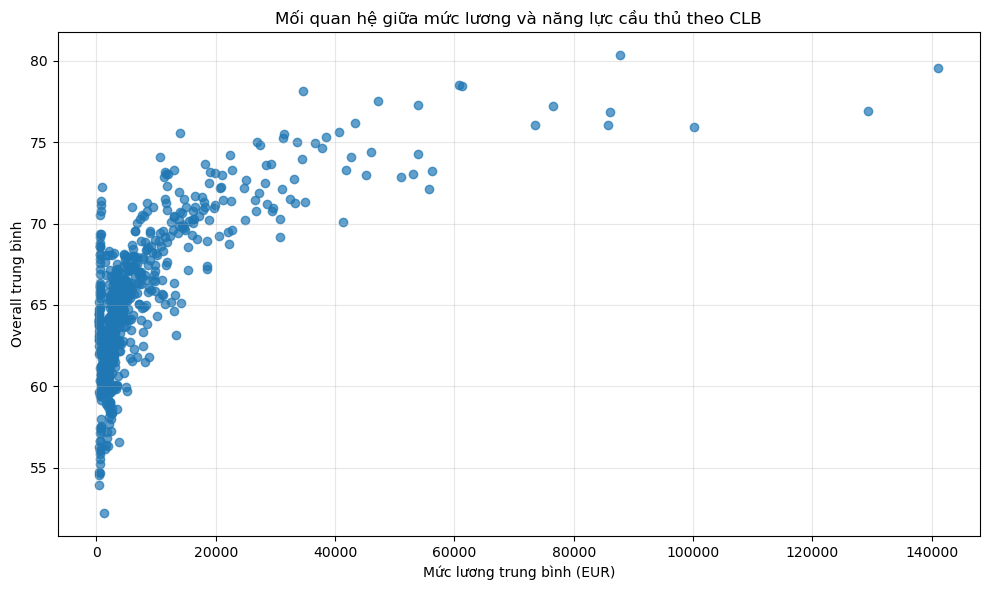

In [11]:
import matplotlib.pyplot as plt

# Chuyển kết quả truy vấn sang Pandas
df_scatter_pd = df_scatter.toPandas()

plt.figure(figsize=(10, 6))

plt.scatter(
    df_scatter_pd["avg_wage"],
    df_scatter_pd["avg_overall"],
    alpha=0.7
)

plt.title("Mối quan hệ giữa mức lương và năng lực cầu thủ theo CLB")
plt.xlabel("Mức lương trung bình (EUR)")
plt.ylabel("Overall trung bình")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("club_wage_vs_overall.png", dpi=200, bbox_inches="tight")
plt.show()

In [12]:
# Tính hệ số tương quan
correlation = df_scatter_pd["avg_wage"].corr(
    df_scatter_pd["avg_overall"]
)

print(f"Hệ số tương quan Pearson: {correlation:.3f}")

Hệ số tương quan Pearson: 0.684


### *Nhận xét: Phân tích mối quan hệ giữa mức lương và năng lực cầu thủ theo câu lạc bộ*

  *- Biểu đồ Scatter Plot của 673 câu lạc bộ (tính trên dữ liệu phiên bản FIFA mới nhất, mỗi cầu thủ một bản ghi) cho thấy các điểm có xu hướng đi lên từ trái sang phải, gợi ý mối quan hệ thuận giữa mức lương trung bình và điểm OVerall trung bình. Phần lớn câu lạc bộ tập trung ở vùng lương trung bình thấp, với Overall khoảng 55-70.*
  
  *- Hệ số tương quan Pearson đạt 0,684, cho thấy mối tương quan tuyến tính thuận tương đối rõ giữa hai biến. Các câu lạc bộ có mức lương trung bình cao hơn thường có xu hướng đạt Overall trung bình cao hơn, phù hợp với xu hướng trên biểu đồ.*
  
  *- Mối quan hệ không hoàn toàn tuyến tính: ở khoảng 10.000 - 40.000 EUR, Overall tăng nhanh theo lương, nhưng với các câu lạc bộ lương trên khoảng 60.000 EUR, Overall chỉ quanh mức 76 - 80 và tăng chậm lại.*
  
  *- Tuy nhiên, tương quan này không chứng minh mức lương cao là nguyên nhân làm tăng năng lực cầu thủ, vì Overall còn liên quan đến nhiều yếu tố khác. Kết quả nên được hiểu là mối liên hệ thống kê giữa mức lương trung bình và điểm Overall trung bình của các câu lạc bộ trong bộ dữ liệu FIFA.*

# TỔNG KẾT
- **Kết nối Spark với Hive Metastore:** Kiểm tra dữ liệu Parquet trên HDFS và đăng ký 3 bảng tổng hợp: `club_summary` (673 dòng), `nationality_summary` (165 dòng), `position_summary` (728 dòng). Các bảng được tính trên dữ liệu phiên bản FIFA mới nhất, mỗi cầu thủ một bản ghi.
- **Truy vấn dữ liệu:** Thực hiện truy vấn Spark SQL đề khai thác dữ liệu từ các bảng Hive.
- **Trực quan hóa dữ liệu:** Xây dựng biểu đồ Bar Chart phân tích Top 10 CLB có mức lương trung bình cao nhất (Manchester City và Real Madrid dẫn đầu) và Scatter Plot khảo sát mối quan hệ giữa mức lương trung bình với điểm Overall trung bình theo CLB.
- **Phân tích tương quan:** Hệ số tương quan Pearson đạt **0,684**, cho thấy mối tương quan tuyến tính thuận tương đối rõ giữa hai biến trong dữ liệu được phân tích.

> *Nhìn chung, nhiệm vụ đã khai thác dữ liệu tổng hợp, thực hiện truy vấn phân tích và trực quan hóa bằng Bar Chart, Scatter Plot. Kết quả giúp làm rõ sự khác biệt về mức lương giữa các câu lạc bộ và mối tương quan giữa mức lương trung bình với năng lực cầu thủ trung bình trong dữ liệu FIFA.*